MovieWriter ffmpeg unavailable.


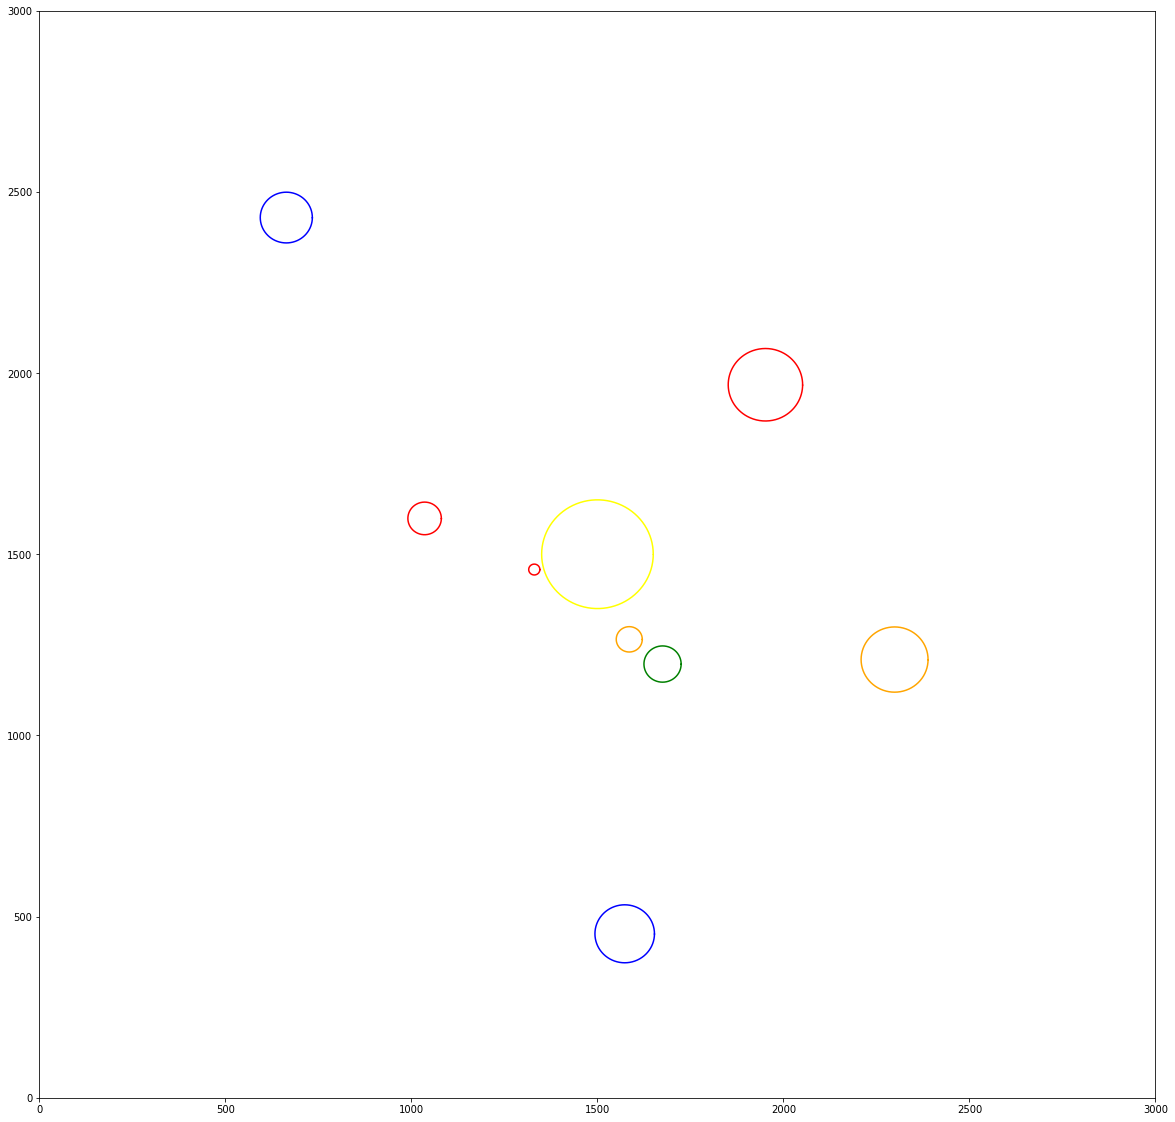

In [20]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import math


class Animation:
    def __init__(self, width, height):
        self.width = width
        self.height = height

        self.planets = {}

    
    def add_planet(self, name, radius,  color, orbit, speed):
        self.planets.update({name: {"radius": radius, "color": color,  "plot":None, "angel" : 0, "speed" : speed, "orbit":orbit}})
        
    def move_planet(self, name):
        self.planets[name]["angel"] += self.planets[name]["speed"]
        
        



    def show(self, plot):
        gs = []

            
        cx = width // 2
        cy = height // 2
        
        for i in self.planets.keys():
            xdata = []
            ydata = []
            self.move_planet(i)
            t = self.planets[i]
            posx = math.cos(math.radians(t["angel"])) * t["orbit"] + cx
            posy = math.sin(math.radians(t["angel"])) * t["orbit"] + cy
            for j in range(360):
                xdata.append(math.cos(math.radians(j)) * t["radius"] + posx)
                ydata.append(math.sin(math.radians(j)) * t["radius"] + posy)

            if t["plot"] is None:
                t["plot"] = plot.plot(xdata, ydata, c=t["color"])
            else:
                t["plot"][0].set_data(xdata, ydata)
            gs.append(t["plot"][0])


        return tuple(gs)


width = 3000
height = 3000

a = Animation(width, height)


#planets
a.add_planet("0", 150,  'yellow', 0, 0)
a.add_planet("1", 15,  'red', 175, 47)
a.add_planet("2", 35,  'orange', 250, 35)
a.add_planet("3", 50,  'green', 350, 30)
a.add_planet("4", 45,  'red', 475, 24)

a.add_planet("5", 100,  'red', 650, 13)
a.add_planet("6", 90,  'orange', 850, 10)

a.add_planet("7", 80,  'blue', 1050, 7)
a.add_planet("8", 70,  'blue', 1250, 6)




fig = plt.figure(figsize=(20,20))
ax = plt.axes(xlim=(0, width), ylim=(0, height))

ax.set_xlim([0, width])
ax.set_ylim([0, height])


def init():
    a.set_k("c", "y", 0)
    return a.show(ax)

dt = 1
def animate(frame):

        

    return a.show(ax)

anim = animation.FuncAnimation(fig, animate,  frames=500, interval=1 )
anim.save(filename = "sasa.gif")